# ML Lab 3 – Activities 1, 2

Name : Aleeha Aiman

Rollno: 23-NTU-CS-1243

Class: BsCs 7th(A)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

---
## Activity 1 – Predict Customer Churn (Logistic Regression)


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score


data2 = pd.read_csv("Bank_Customer_Churn.csv")
print(data2.shape)
data2.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
le_geo = LabelEncoder()
le_gender = LabelEncoder()

data2['Geography'] = le_geo.fit_transform(data2['Geography'])
data2['Gender'] = le_gender.fit_transform(data2['Gender'])

X2 = data2[['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'IsActiveMember', 'Geography', 'Gender']]
y2 = data2['Exited']   # 1 = churned, 0 = stayed

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

In [4]:
log_model = LogisticRegression()
log_model.fit(X2_train_scaled, y2_train)

y2_pred = log_model.predict(X2_test_scaled)
y2_proba = log_model.predict_proba(X2_test_scaled)[:, 1]

In [5]:
print("Accuracy: ", accuracy_score(y2_test, y2_pred))
print("Precision:", precision_score(y2_test, y2_pred))
print("Recall:   ", recall_score(y2_test, y2_pred))
print("F1-score: ", f1_score(y2_test, y2_pred))

Accuracy:  0.8155
Precision: 0.6
Recall:    0.183206106870229
F1-score:  0.2807017543859649


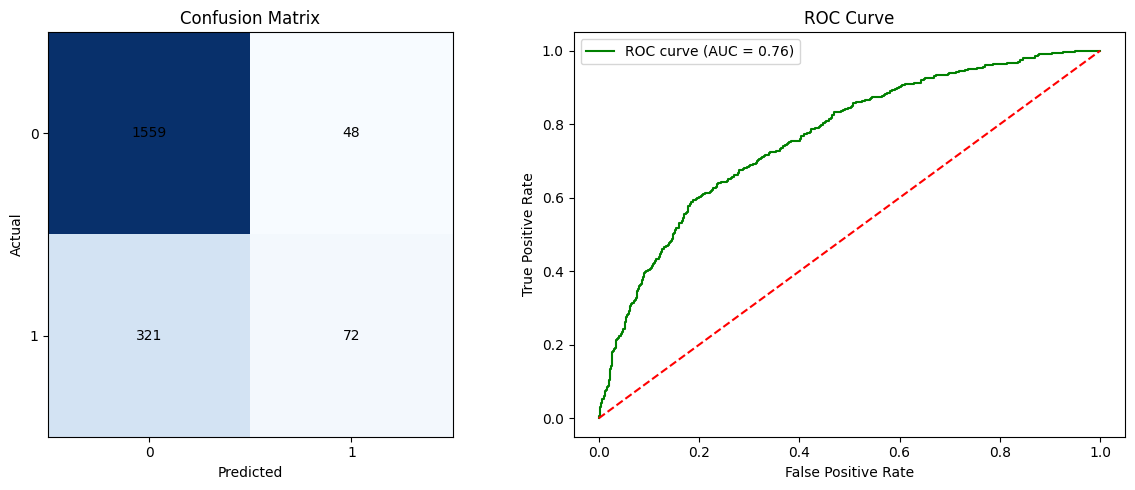

In [6]:
cm = confusion_matrix(y2_test, y2_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', color='black')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])

fpr, tpr, _ = roc_curve(y2_test, y2_proba)
auc = roc_auc_score(y2_test, y2_proba)
axes[1].plot(fpr, tpr, color='green', label=f'ROC curve (AUC = {auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Activity 2 – Predict Car Fuel Efficiency / MPG (Linear & Polynomial Regression)


In [7]:
from sklearn.preprocessing import PolynomialFeatures


data3 = pd.read_csv("Auto_MPG.csv")
data3 = data3.dropna()          # horsepower has a few missing values
print(data3.shape)
data3.head()

(392, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [8]:
features3 = ['horsepower', 'displacement', 'weight', 'acceleration']
X3 = data3[features3]
y3 = data3['mpg']

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42)

In [9]:
lin3 = LinearRegression()
lin3.fit(X3_train, y3_train)
y3_pred_lin = lin3.predict(X3_test)

print("Linear Regression:")
print("  RMSE:", np.sqrt(mean_squared_error(y3_test, y3_pred_lin)))
print("  R2:  ", r2_score(y3_test, y3_pred_lin))

Linear Regression:
  RMSE: 4.250402541240524
  R2:   0.6460478972647503


In [10]:
results = {}
for d in [2, 3, 4]:
    poly3 = PolynomialFeatures(degree=d)
    X3_train_poly = poly3.fit_transform(X3_train)
    X3_test_poly = poly3.transform(X3_test)

    poly_model3 = LinearRegression()
    poly_model3.fit(X3_train_poly, y3_train)
    y3_pred_poly = poly_model3.predict(X3_test_poly)

    rmse = np.sqrt(mean_squared_error(y3_test, y3_pred_poly))
    r2 = r2_score(y3_test, y3_pred_poly)
    results[d] = (rmse, r2)
    print(f"Degree {d}: RMSE = {rmse:.2f}, R2 = {r2:.4f}")

Degree 2: RMSE = 4.05, R2 = 0.6790
Degree 3: RMSE = 4.54, R2 = 0.5955
Degree 4: RMSE = 4.90, R2 = 0.5294


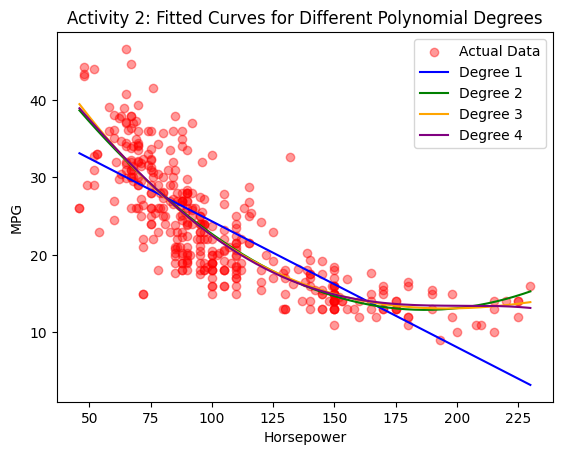

In [11]:
Xh = data3[['horsepower']]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, y3, test_size=0.2, random_state=42)

x_grid = pd.DataFrame(np.linspace(Xh['horsepower'].min(), Xh['horsepower'].max(), 200), columns=['horsepower'])

plt.scatter(Xh, y3, color='red', alpha=0.4, label='Actual Data')
for d, color in zip([1, 2, 3, 4], ['blue', 'green', 'orange', 'purple']):
    p = PolynomialFeatures(degree=d)
    Xh_poly = p.fit_transform(Xh_train)
    m = LinearRegression().fit(Xh_poly, yh_train)
    plt.plot(x_grid, m.predict(p.transform(x_grid)), color=color, label=f'Degree {d}')

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Activity 2: Fitted Curves for Different Polynomial Degrees')
plt.legend()
plt.show()